# Weight-space programming in one small notebook

One model (Qwen2.5-0.5B) and four steps. The first three use one task (antonyms):

1. **The model**: what it contains, and which numbers an edit touches.
2. **In-context learning (ICL)**: the model fails without examples and succeeds with sixteen. The difference
   between the two is a vector, and adding that vector by hand makes the model succeed without examples.
3. **One real edit**: the weight change that Gemini 4 Argon wrote in run `antonym_gemini150_s0`, applied here
   and checked number by number.
4. **Six more edits**: weight changes written by Claude Fable 5.1, Claude Opus 5.5 and GPT-6 Astra on the
   other tasks, applied and checked in the same way.

Lines that end in `ok` compare a value computed here with the value stored in the paper's result files.

**To run it** you need `torch` and `transformers` (and `datasets` for the WikiText checks), started from
inside the repository; the README gives the commands. A GPU is not required: the model has 494M parameters.
No API key is needed and no editor is run: every weight change applied here was written during the paper's
experiments and is stored in `runs/`. The outputs saved in this file were produced on a laptop CPU.

In [1]:
import json, os, re, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")      # library warnings are not needed here
import torch
import torch.nn.functional as F

# ROOT is the top folder of the repository (the one that holds wsp/, results/ and runs/).
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
here = Path.cwd()
ROOT = Path(os.environ["WSP_ROOT"]) if os.environ.get("WSP_ROOT") else next(p for p in [here, *here.parents] if (p / "wsp" / "common.py").exists())
sys.path.insert(0, str(ROOT))
from wsp import common                 # the prompt format and the exact-match scorer used in the paper
from wsp.tasks import get_split        # the task data and the 16 / 30 / rest split

# RUN     the run examined in part 3: task antonym, editor Gemini 4 Argon with 150 turns, data split 0.
# STORED  the evaluation of that run made for the paper (accuracy, agreement with ICL, cosines, perplexity).
# UNITS   the measurements made for the paper on each hidden unit that the run rewrote, one entry per layer.
RUN = "antonym_gemini150_s0"
STORED = json.load(open(ROOT / "results" / "v2" / f"{RUN}.json"))                 # the paper's evaluation of this run
UNITS = json.load(open(ROOT / "results" / "unit_report.json"))[RUN]["layers"]     # its per-unit measurements

# check() prints a value computed in this notebook next to the stored one and writes "ok" when the two agree
# to `nd` decimals.  CHECKS collects the outcomes so that the last cell can count them.
CHECKS = []
def check(what, here, stored, nd=3):
    ok = abs(here - stored) <= 10 ** -nd
    CHECKS.append(ok)
    print(f"{what:<60s} here {here:>9.{nd}f}   stored {stored:>9.{nd}f}   {'ok' if ok else 'DIFFERS'}")

## 1. The model

Qwen2.5-0.5B is a stack of 24 identical layers. A vector of 896 numbers per token, the *residual stream*,
runs through the stack; every layer reads it and adds to it, first with attention and then with an MLP.

**The whole model in one picture.** Read it from top to bottom, following the orange line:

1. *The start.* The prompt is cut into tokens, and each token is replaced by a vector of 896 numbers.
2. *One layer.* Attention lets each token read from the earlier ones; the MLP then adds what its 4,864 hidden
   units fire. Both add their result to the orange line. The blue marks show one hidden unit: the three
   vectors that an edit rewrites.
3. *The end.* After the 24th layer the vector at the final token is turned into a score for every possible
   next token.

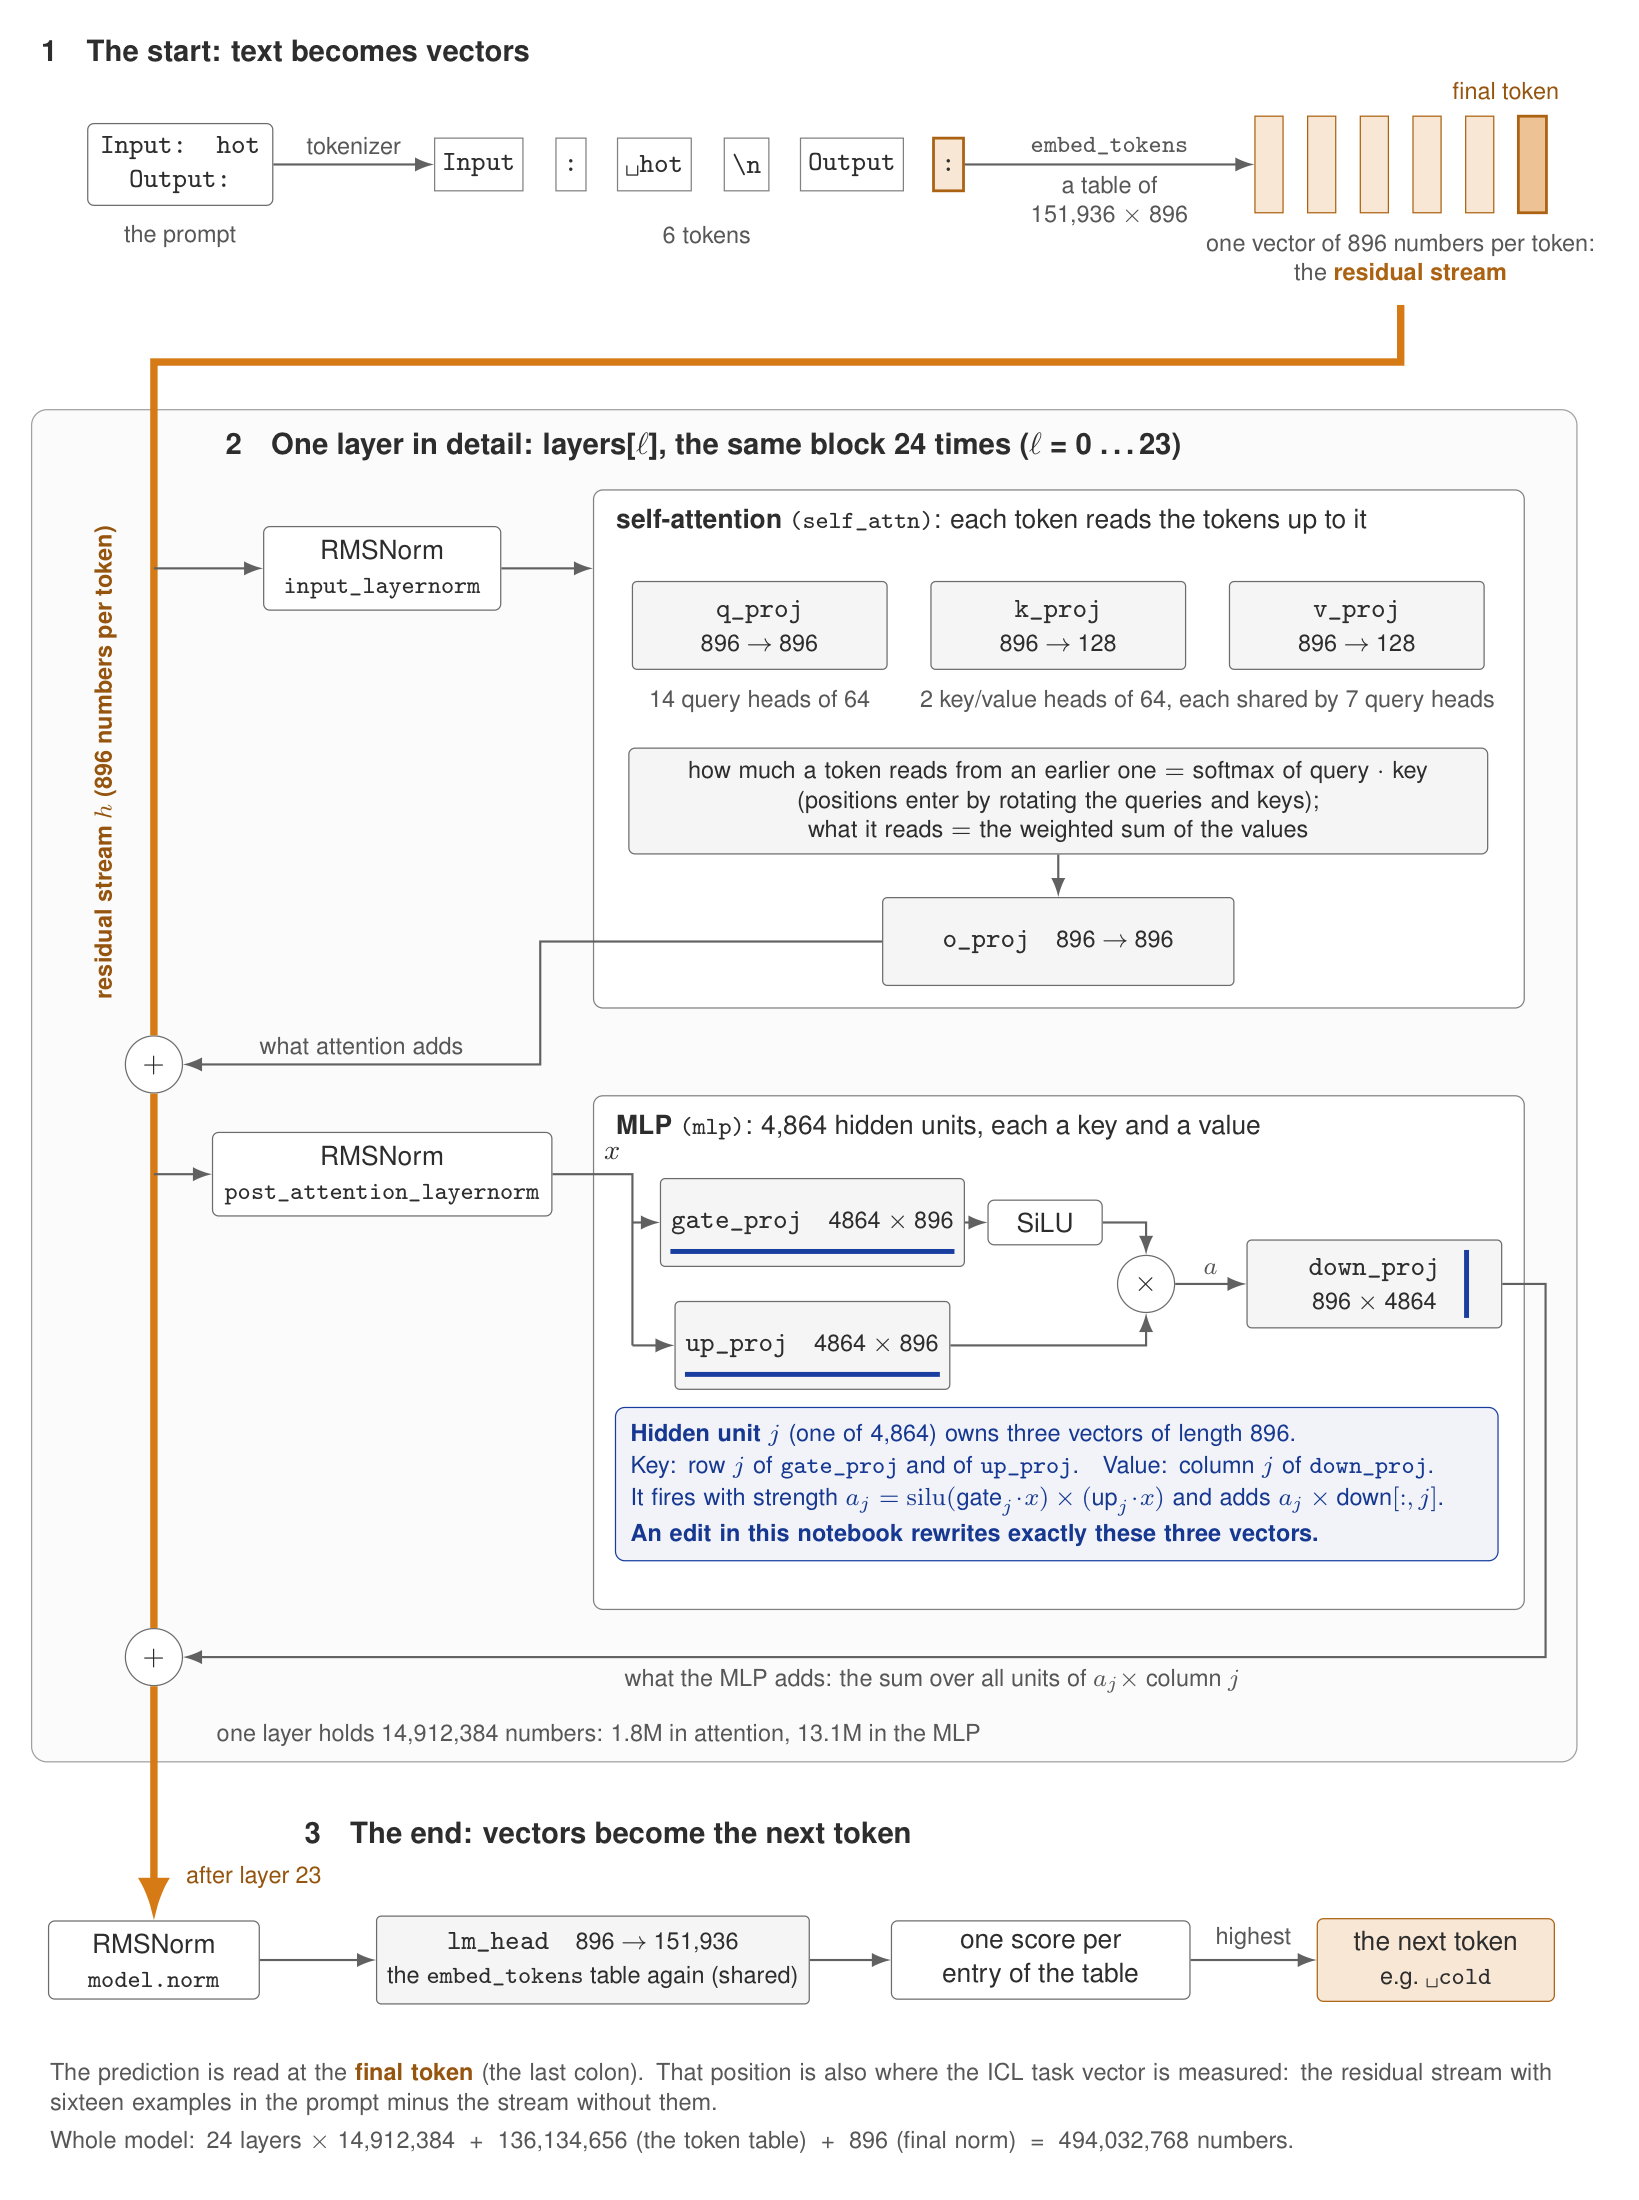

The drawing is `figures/qwen_schematic.png`; every size in it is read from the model's own files.

In [2]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()       # keep the output to what this notebook prints

# device: the GPU with the most free memory if there is one, otherwise the CPU.
NAME = "Qwen/Qwen2.5-0.5B"
if torch.cuda.is_available():
    free = [torch.cuda.mem_get_info(i)[0] for i in range(torch.cuda.device_count())]
    device = f"cuda:{free.index(max(free))}"
else:
    device = "cpu"

# tok    the tokenizer: turns text into token ids and back.  Prompts in a batch have different lengths, so the
#        shorter ones are padded; padding on the LEFT keeps the final token of every prompt at position -1.
# model  the language model.  Given the tokens so far it scores every possible next token.
tok = AutoTokenizer.from_pretrained(NAME)
tok.padding_side = "left"              # so that the last position of every prompt is its final token
try:
    model = AutoModelForCausalLM.from_pretrained(NAME, dtype=torch.float32)
except TypeError:
    model = AutoModelForCausalLM.from_pretrained(NAME, torch_dtype=torch.float32)
model = model.to(device).eval()
for p in model.parameters():
    p.requires_grad_(False)            # no gradients anywhere in this notebook

# n_params  how many numbers (weights) the model has in total.
# layers    the 24 blocks of the model, layers[0] ... layers[23].  Each block has an attention part
#           (layers[L].self_attn) and an MLP part (layers[L].mlp).
# model.config.hidden_size = 896 is the width of the residual stream: the length of the vector each token carries.
n_params = sum(p.numel() for p in model.parameters())
layers = model.model.layers
print(f"layers: {len(layers)}   residual width: {model.config.hidden_size}   parameters: {n_params:,}")

layers: 24   residual width: 896   parameters: 494,032,768


Each layer's MLP holds three matrices. For an input `x` (896 numbers) it computes

`MLP(x) = down_proj( silu(gate_proj x) * (up_proj x) )`

through 4,864 *hidden units*. Unit `j` owns exactly three vectors of length 896:

| vector | role |
|---|---|
| row `j` of `gate_proj` and row `j` of `up_proj` | the **key**: they decide when the unit is active, `a_j = silu(gate_j . x) * (up_j . x)` |
| column `j` of `down_proj` | the **value**: the unit adds `a_j` times this column to the residual stream |

**This is what gets edited in part 3**: one unit in each of 13 layers, three vectors per unit, nothing else.

**Names used in this notebook**

| name | what it is |
|---|---|
| residual stream | the vector of 896 numbers each token carries through the 24 layers; every layer adds to it |
| `x` | the input of an MLP: the residual stream at that point, normalised |
| `gate_proj`, `up_proj` | the matrices the paper calls W_gate and W_up, shape 4864 x 896; row `j` belongs to unit `j` |
| `down_proj` | W_down, shape 896 x 4864; column `j` belongs to unit `j` |
| `a_j` | the activation of unit `j` on an input: `silu(gate_j . x) * (up_j . x)`, one number |
| key, value | the key is unit `j`'s gate row and up row (when it fires); the value is its down column (what it adds) |
| zero-shot prompt | `Input: hot` / `Output:` with nothing before it |
| ICL prompt | the same query with the 16 training pairs written before it |
| task vector | residual stream with the examples minus without them, at the final token, averaged over queries |
| delta | the list of weight positions an editor changed and the amount added at each |
| hook | a function PyTorch calls while the model runs, used here to read or change the stream |

In [3]:
# The three matrices of one MLP.  "proj" is short for projection: a plain matrix multiplication with no bias.
#   mlp.gate_proj.weight   W_gate in the paper, shape (4864, 896).  Row j is a direction in the residual stream;
#                          its dot product with the input x says how strongly unit j should open.
#   mlp.up_proj.weight     W_up, shape (4864, 896).  Row j gives the second factor of unit j's activation.
#                          "up" because it goes from 896 numbers up to 4,864.
#   mlp.down_proj.weight   W_down, shape (896, 4864).  Column j is the vector unit j writes back into the residual
#                          stream.  "down" because it goes from 4,864 numbers back down to 896.
# silu(z) = z * sigmoid(z): close to 0 when z is very negative, close to z when z is large.  So a unit whose
# gate_j . x is very negative contributes nothing, whatever its up row and its down column are.
mlp = layers[13].mlp
print(mlp, "\n")
for part in ("gate_proj", "up_proj", "down_proj"):
    print(f"{part:10s} weight shape {tuple(getattr(mlp, part).weight.shape)}")
per_unit = 3 * model.config.hidden_size
print(f"\none hidden unit = 3 x {model.config.hidden_size} = {per_unit:,} numbers = {100 * per_unit / n_params:.5f}% of the model")

Qwen2MLP(
  (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
  (up_proj): Linear(in_features=896, out_features=4864, bias=False)
  (down_proj): Linear(in_features=4864, out_features=896, bias=False)
  (act_fn): SiLUActivation()
) 

gate_proj  weight shape (4864, 896)
up_proj    weight shape (4864, 896)
down_proj  weight shape (896, 4864)

one hidden unit = 3 x 896 = 2,688 numbers = 0.00054% of the model


### A hidden unit in plain words: a lock and what is behind it

Think of each hidden unit as a small lock with something stored behind it. `gate_proj` and `up_proj` together are
the lock, which is why they are called the **key**. `down_proj` holds what is behind it, the **value**.

**What a row is.** Row `j` of `gate_proj` is a list of 896 numbers, the same length as the vector `x` that arrives
at the MLP. Multiply the two lists position by position and add everything up: the result is one number, a
*score* for how much `x` looks like the pattern stored in that row. Row `j` of `up_proj` does the same with a
pattern of its own. So unit `j` asks the input two questions and gets two scores.

**What each score does.**

- The **gate score** is a switch. It goes through SiLU, which turns a very negative score into about 0 and leaves
  a large positive score almost as it is. If the input does not match the gate pattern, the unit is off.
- The **up score** is the amount. It says how strongly the unit fires once the switch is open.

The unit's activation is the two multiplied: `a_j = silu(gate score) * (up score)`.

| gate score | after SiLU | up score | activation `a_j` |
|---|---|---|---|
| +8 (the input matches) | about 8 | 2 | about 16 |
| -8 (it does not match) | about 0 | 2 | about 0 |
| -8 | about 0 | 100 | still about 0 |

The last row is the important one: when the gate is closed nothing gets through, whatever the other numbers are.

**What happens when it fires.** The unit adds `a_j` times its column of `down_proj` to the residual stream. That
column is the value, explained next.

### The value in plain words: what the unit adds

Column `j` of `down_proj` is also a list of 896 numbers, the same length as the residual stream. It is a fixed
*direction*: the one thing this unit knows how to add.

When the unit fires with strength `a_j`, the model takes that list, multiplies every number in it by `a_j`, and
adds the result to the residual stream at that token.

| the column (first numbers) | activation `a_j` | what is added to the stream |
|---|---|---|
| 0.5, -1, 2, ... | 3 | 1.5, -3, 6, ... |
| 0.5, -1, 2, ... | 10 | 5, -10, 20, ... |
| 0.5, -1, 2, ... | 0 | nothing |

So the two halves have separate jobs. The key decides **when** the unit acts and **how strongly**. The value
decides **what** it adds, and that never changes from one input to the next: only its size does.

Why adding a direction matters: everything after this point reads the residual stream. The later layers and, at
the end, the output head turn it into the next token. Push the stream in the right direction and a different
token comes out. The whole MLP of a layer adds the sum of all its 4,864 units, each with its own `a_j` and its own
column.

### The key and the value in an edit

An editor that rewrites a unit chooses both halves.

- **The key it writes** is a pattern that matches one situation only: the final token of an `Input: ... Output:`
  prompt. To find such a pattern the editor runs the model on a few prompts and on other text, looks at the
  vector `x` in each case, and builds a direction that points towards the first kind and away from the second
  (a *probe*). It writes that direction, scaled up, into the unit's gate row, and chooses the up row so that the
  activation comes out at the size it wants. On any other text the gate score is then very negative and the unit
  stays at zero, which is why the rest of the model behaves as before.
- **The value it writes** is the task vector of part 2: what the sixteen examples would have added to the residual
  stream at that point. Because the stream receives `a_j` times the column, the editor stores the task vector
  divided by the activation the unit will have, so that activation times column comes out as the task vector.
  An editor can also split the job over several units, each adding a share.

Put together: *when the input looks like the end of a task prompt, add what the examples would have added.*
In part 3, Check 2 opens one of Gemini's units and prints its two scores on real inputs, and Check 3 compares
what each unit adds with the task vector.

## 2. In-context learning and the task vector

The task: given a word, answer with its opposite. The split is the paper's: 16 training pairs, 30 development
items and 190 test items. A *zero-shot* prompt contains only the query. An *ICL* prompt puts the 16 training
pairs in front of it.

In [4]:
# get_split(task, seed) returns three lists of items; an item is (input word, [accepted answers]).
#   train  the 16 pairs every method is given          dev  30 items used to tune the baselines
#   test   the remaining 190 items, never shown to an editor
# set_decoding_length fixes how many tokens the model may generate, enough for the longest answer of the task.
# demos  the 16 training pairs as (input, answer): the examples placed in an ICL prompt.
# common.make_prompt(x) writes the zero-shot prompt "Input: x\nOutput:"; with demos it writes them first.
train, dev, test = get_split("antonym", 0)
common.set_decoding_length(train + dev + test, tok)
demos = [(x, ys[0]) for x, ys in train]

print("zero-shot prompt:\n" + common.make_prompt("hot"))
print("\nICL prompt (first 3 of the 16 examples shown):\n" + common.make_prompt("hot", demos[:3]))

zero-shot prompt:
Input: hot
Output:

ICL prompt (first 3 of the 16 examples shown):
Input: birth
Output: death

Input: rare
Output: common

Input: death
Output: life

Input: hot
Output:


In [5]:
# common.evaluate(model, tok, items, demos) builds a prompt for every item, lets the model generate greedily and
# scores the first line of its output by exact match.  It returns a dict with
#   "accuracy"     share of items answered correctly        "generations"  the cleaned output for each item
# zs  = zero-shot (no examples in the prompt)               icl = the 16 examples in the prompt
zs = common.evaluate(model, tok, test)               # no examples
icl = common.evaluate(model, tok, test, demos)       # 16 examples in the prompt
check("zero-shot accuracy on the 190 test items", zs["accuracy"], STORED["acc_zero_shot_base"])
check("16-shot ICL accuracy", icl["accuracy"], STORED["acc_icl_base_perms"][0])
print(f"(the paper reports the mean over three orders of the examples: {100 * STORED['acc_icl_base']:.1f}%)\n")
print(f"{'input':10s} {'gold':10s} {'zero-shot':12s} {'ICL':10s}")
for i in range(6):
    print(f"{test[i][0]:10s} {test[i][1][0]:10s} {zs['generations'][i]:12s} {icl['generations'][i]:10s}")

zero-shot accuracy on the 190 test items                     here     0.000   stored     0.000   ok
16-shot ICL accuracy                                         here     0.937   stored     0.937   ok
(the paper reports the mean over three orders of the examples: 94.2%)

input      gold       zero-shot    ICL       
laugh      cry        laugh        cry       
near       far        1            far       
poor       rich       1            rich      
heavy      light      1            light     
multiply   divide     10000        divide    
subtract   add        1            add       


**The task vector.** Take the residual stream at the final token of the prompt, once with the examples and once
without, and subtract. Averaged over queries, the difference is one vector per layer: what the sixteen examples
add. If ICL really works through this vector, adding it by hand to a zero-shot prompt should be enough.

In [6]:
# hidden(prompts) returns a tensor of shape [number of prompts, 25, 896].  For each prompt it holds the residual
# stream at the FINAL token, at 25 depths: index 0 is the token embedding, index L + 1 is the stream after
# layer L.  That is why the code below writes task_vector[L + 1] for "after layer L".
def hidden(prompts):
    """Residual stream at the final token after every layer: [prompts, 25, 896]."""
    return common.last_token_hidden(model, tok, prompts)

# zs_dev / icl_dev  the same 30 development queries written without and with the 16 examples.
# task_vector       (stream with examples) - (stream without), averaged over the 30 queries: one vector of
#                   length 896 for each of the 25 depths.  This is the "ICL task vector".
zs_dev = [common.make_prompt(x) for x, _ in dev]
icl_dev = [common.make_prompt(x, demos) for x, _ in dev]
task_vector = (hidden(icl_dev) - hidden(zs_dev)).mean(0)          # [25, 896], measured on the development items
print("length of the task vector after layers 8, 13, 20:", [round(float(task_vector[L + 1].norm()), 1) for L in (8, 13, 20)])

# add_at_layer installs a "forward hook": a function PyTorch calls every time layer L has produced its output.
#   output[0], called h, has shape [batch, tokens, 896]: the residual stream after layer L for every token.
#   h[:, -1, :] += vec   adds the vector at the last token only.
#   if h.shape[1] > 1    while generating, the model sees the whole prompt once and afterwards one new token at a
#                        time; the test keeps the addition to the prompt's final token and off the answer tokens.
# It returns a handle; handle.remove() takes the hook off again, leaving the model exactly as it was.
def add_at_layer(L, vec):
    """Add `vec` to the output of layer L at the final token of the prompt."""
    def hook(module, inputs, output):
        h = output[0] if isinstance(output, tuple) else output
        if h.shape[1] > 1:
            h[:, -1, :] += vec.to(h.device, h.dtype)
        return output
    return layers[L].register_forward_hook(hook)

L = STORED["task_vector_patch"]["layer"]                          # layer 13, chosen on the development items
handle = add_at_layer(L, task_vector[L + 1])
patched = common.evaluate(model, tok, test)                       # still zero-shot prompts
handle.remove()
check(f"zero-shot accuracy with the task vector added at layer {L}", patched["accuracy"], STORED["task_vector_patch"]["test_acc"])

length of the task vector after layers 8, 13, 20: [7.1, 13.7, 31.2]
zero-shot accuracy with the task vector added at layer 13    here     0.853   stored     0.853   ok


No weight has changed so far: the vector was added from outside while the model ran. The question of the paper is
what a language model does when it is asked to make the model solve the task **by changing its weights**.

## 3. One edit written by Gemini 4 Argon

Gemini was given the 16 training pairs, this model in a Python session, 50 forward passes, and no gradients.
It was told nothing about ICL or task vectors. The file below is everything it left behind: a list of
positions in the weights and the amount added at each.

In [7]:
# delta is the weight change Gemini left, as a dict:  name of a weight matrix -> {"idx", "val", "shape"}
#   "shape"  the shape of that matrix, e.g. (4864, 896) for a gate_proj
#   "idx"    the positions that changed, numbered as if the matrix were flattened into one long row
#   "val"    the amount added at each of those positions
# A flat position p in a matrix with n_cols columns sits at  row = p // n_cols,  column = p % n_cols.
# For gate_proj and up_proj the changed positions all share one ROW (the key of one unit); for down_proj they
# all share one COLUMN (the value of the same unit).  The loop below checks exactly that.
DELTA = ROOT / "runs" / RUN / "delta.pt"                           # the file written at the end of the run
delta = torch.load(DELTA, map_location="cpu", weights_only=True)["delta"]

edited_units = {}                                                  # layer -> unit index
print(f"{'layer':>5s} {'unit':>6s}   numbers changed in gate row / up row / down column")
for name, d in delta.items():
    L, part = re.search(r"layers\.(\d+)\.mlp\.(gate|up|down)_proj\.weight", name).groups()
    rows, cols = d["idx"] // d["shape"][1], d["idx"] % d["shape"][1]
    unit = (cols if part == "down" else rows).unique()             # a row of gate/up, a column of down
    assert len(unit) == 1, "more than one unit touched in this matrix"
    edited_units.setdefault(int(L), {})[part] = (int(unit), len(d["idx"]))
for L, parts in edited_units.items():
    assert len({u for u, _ in parts.values()}) == 1                # the same unit in all three matrices
    print(f"{L:>5d} {parts['gate'][0]:>6d}   {parts['gate'][1]} / {parts['up'][1]} / {parts['down'][1]}")
edited_units = {L: parts["gate"][0] for L, parts in edited_units.items()}

# edited_units  now maps layer -> index j of the unit rewritten in that layer.
# n_changed     total number of weights the edit touches.
n_changed = sum(len(d["idx"]) for d in delta.values())
print(f"\n{len(delta)} matrices touched, {len(edited_units)} units, {n_changed:,} numbers = {100 * n_changed / n_params:.4f}% of the model")
check("numbers changed", n_changed, STORED["edit_stats"]["n_changed"], nd=0)

layer   unit   numbers changed in gate row / up row / down column
    8   4750   896 / 896 / 896
    9    499   896 / 896 / 896
   10   1591   896 / 896 / 896
   11   1060   896 / 896 / 896
   12   2422   896 / 896 / 896
   13   4299   896 / 896 / 896
   14    887   896 / 896 / 896
   15    355   896 / 896 / 896
   16    854   896 / 896 / 896
   17    897   896 / 896 / 896
   18   3134   896 / 896 / 896
   19    302   896 / 896 / 896
   20   1804   896 / 896 / 896

39 matrices touched, 13 units, 34,944 numbers = 0.0071% of the model
numbers changed                                              here     34944   stored     34944   ok


So the whole edit is 13 hidden units, one per layer from 8 to 20, each with its full key (gate row, up row) and
value (down column) rewritten. Before applying it, three measurements on the untouched model:
where each of these units ranked among the 4,864 units of its layer, the residual stream on the test prompts,
and the perplexity on ordinary text.

In [8]:
# mlp_inputs uses a "forward PRE-hook": a function called just before a layer's MLP runs, which receives the
# MLP's input.  That input is x in the formula: the residual stream after this layer's attention, normalised.
# Only x at the final token is kept.  Result: {layer: tensor [number of prompts, 896]}.
@torch.no_grad()
def mlp_inputs(prompts, batch=8):
    """The exact input x of each edited layer's MLP at the final token: {layer: [prompts, 896]}."""
    got = {L: [] for L in edited_units}
    hooks = [layers[L].mlp.register_forward_pre_hook(lambda m, inp, L=L: got[L].append(inp[0][:, -1, :].float().cpu())) for L in edited_units]
    for i in range(0, len(prompts), batch):
        model(**tok(prompts[i:i + batch], return_tensors="pt", padding=True).to(device))
    for h in hooks:
        h.remove()
    return {L: torch.cat(v) for L, v in got.items()}

# activations computes a_j = silu(gate_j . x) * (up_j . x) for every prompt and every unit of layer L (or only
# for the listed units).  g and u are W_gate and W_up; "x @ g.T" takes the dot product of each x with each row.
# Result: tensor [number of prompts, number of units].  a_j is how strongly unit j fires on that prompt.
def activations(x, L, units=None):
    """a_j = silu(gate_j . x) * (up_j . x) with the weights the model holds right now."""
    g, u = layers[L].mlp.gate_proj.weight.float().cpu(), layers[L].mlp.up_proj.weight.float().cpu()
    if units is not None:
        g, u = g[units], u[units]
    return F.silu(x @ g.T) * (x @ u.T)

# wiki  the WikiText-2 test text: ordinary English, used as "text that is not the task".
try:
    from datasets import load_dataset
    wiki = [t for t in load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")["text"]]
except Exception as e:
    wiki = None
    print("WikiText is not available here, so the checks that need it are skipped:", type(e).__name__)

# text_windows  32 pieces of that text, 64 tokens each, to see how units behave on ordinary text.
def text_windows(n=32, win=64):
    ids = tok("\n".join(t for t in wiki if len(t) > 200), return_tensors="pt")["input_ids"][0][: n * win]
    return [tok.decode(ids[i * win:(i + 1) * win]) for i in range(n)]

# perplexity  how well the model predicts ordinary text (lower is better): exp of the average loss over 24
#             windows of 512 tokens.  If an edit left it unchanged, it did not disturb normal language modelling.
@torch.no_grad()
def perplexity(n_windows=24, win=512):
    ids = tok("\n\n".join(t for t in wiki if t.strip())[:400000], return_tensors="pt")["input_ids"][0][: n_windows * win]
    nll = sum(float(model(input_ids=ids[i:i + win][None].to(device), labels=ids[i:i + win][None].to(device)).loss) for i in range(0, len(ids) - win + 1, win))
    return float(torch.exp(torch.tensor(nll / (len(ids) // win))))

# own      32 antonym queries as zero-shot prompts          own_icl  the same queries with the 16 examples
# others   zero-shot prompts of the five other tasks: same "Input:/Output:" format, different task
# tv32     the task vector measured on these 32 queries (the sample the paper's per-unit report uses)
# zs_test / icl_test   all 190 test queries without and with the examples
# H_zs, H_icl          their residual streams at the final token, shape [190, 25, 896]
# logits_zs, logits_icl  the model's score for every possible next token at the final token, shape [190, vocabulary]
own = [common.make_prompt(x) for x, _ in test[:32]]                 # antonym prompts
own_icl = [common.make_prompt(x, demos) for x, _ in test[:32]]
others = [common.make_prompt(x) for t in ("capital", "past_tense", "en_fr", "times_2", "add_7") for x, _ in get_split(t, 0)[2][:32]]
tv32 = (hidden(own_icl) - hidden(own)).mean(0)                      # the task vector on these 32 queries

zs_test = [common.make_prompt(x) for x, _ in test]
icl_test = [common.make_prompt(x, demos) for x, _ in test]
H_zs, H_icl = hidden(zs_test), hidden(icl_test)
logits_zs, logits_icl = common.last_token_logits(model, tok, zs_test), common.last_token_logits(model, tok, icl_test)

# importance of a unit = (how strongly it fires on ordinary text, on average) x (length of the vector it writes).
# pct is the share of the layer's 4,864 units that are LESS important than unit j: near 0 means nearly silent.
if wiki:
    text = text_windows()
    x_text = mlp_inputs(text)
    print("how quiet each unit was before the edit (0 = the least important unit of its layer on ordinary text)")
    for L, j in edited_units.items():
        importance = activations(x_text[L], L).abs().mean(0) * layers[L].mlp.down_proj.weight.float().cpu().norm(dim=0)
        pct = 100 * float((importance < importance[j]).float().mean())
        check(f"  layer {L:2d} unit {j:4d}: percentile of importance", pct, UNITS[str(L)]["units"][0]["silence_pct_importance"], nd=1)
    ppl_before = perplexity()
    check("WikiText-2 perplexity before the edit", ppl_before, STORED["wikitext_ppl"]["base"], nd=2)

how quiet each unit was before the edit (0 = the least important unit of its layer on ordinary text)
  layer  8 unit 4750: percentile of importance               here       0.1   stored       0.1   ok
  layer  9 unit  499: percentile of importance               here       2.7   stored       2.7   ok
  layer 10 unit 1591: percentile of importance               here       0.2   stored       0.2   ok
  layer 11 unit 1060: percentile of importance               here       2.4   stored       2.4   ok
  layer 12 unit 2422: percentile of importance               here       1.9   stored       1.9   ok
  layer 13 unit 4299: percentile of importance               here      37.6   stored      37.6   ok
  layer 14 unit  887: percentile of importance               here       1.6   stored       1.6   ok
  layer 15 unit  355: percentile of importance               here       2.6   stored       2.6   ok
  layer 16 unit  854: percentile of importance               here       1.3   stored       1.3   ok

Twelve of the thirteen units were among the least important 3% of their layer (the one in layer 13 was not).
**Now apply the edit**: add each stored amount at its position.
The original values are kept so that the edit can be undone at the end.

In [9]:
# params    name -> weight tensor of the live model.
# .data.view(-1) looks at a matrix as one long row without copying it, so writing through it changes the model.
# original  the values at the positions about to change, saved so that the last check can put them back.
params = dict(model.named_parameters())
original = {name: params[name].data.view(-1)[d["idx"].to(device)].clone() for name, d in delta.items()}
for name, d in delta.items():
    params[name].data.view(-1)[d["idx"].to(device)] += d["val"].to(device)
print(f"applied: {n_changed:,} numbers changed in {len(delta)} matrices")

applied: 34,944 numbers changed in 39 matrices


### Check 1: the edited model solves the task without examples

In [10]:
# ed    the edited model on zero-shot prompts.          same  share of items where ed and icl give the same output.
ed = common.evaluate(model, tok, test)                              # zero-shot prompts, edited weights
check("zero-shot accuracy after the edit, 190 test items", ed["accuracy"], STORED["acc_zero_shot_edited"])
check("  on the 16 training pairs", common.evaluate(model, tok, train)["accuracy"], STORED["acc_zero_shot_edited_train"])
check("  on the 30 development items (never shown to Gemini)", common.evaluate(model, tok, dev)["accuracy"], STORED["acc_zero_shot_edited_dev"])
same = sum(a == b for a, b in zip(ed["generations"], icl["generations"])) / len(test)
check("share of test items where it gives the same answer as ICL", same, STORED["agree_edited_vs_icl"])
print(f"\n{'input':10s} {'gold':10s} {'before':12s} {'ICL':10s} {'after the edit':14s}")
for i in range(6):
    print(f"{test[i][0]:10s} {test[i][1][0]:10s} {zs['generations'][i]:12s} {icl['generations'][i]:10s} {ed['generations'][i]:14s}")

zero-shot accuracy after the edit, 190 test items            here     0.905   stored     0.905   ok
  on the 16 training pairs                                   here     1.000   stored     1.000   ok
  on the 30 development items (never shown to Gemini)        here     0.967   stored     0.967   ok
share of test items where it gives the same answer as ICL    here     0.868   stored     0.868   ok

input      gold       before       ICL        after the edit
laugh      cry        laugh        cry        cry           
near       far        1            far        far           
poor       rich       1            rich       rich          
heavy      light      1            light      light         
multiply   divide     10000        divide     divide        
subtract   add        1            add        add           


### Check 2: the keys fire on the prompt format and stay silent on ordinary text

For each rewritten unit: its activation at the final token of antonym prompts, of prompts from the other five
tasks (same `Input:`/`Output:` format, different task), and of ordinary text.

In [11]:
# x_own / x_others / x_text  the MLP inputs of the edited model on antonym prompts, other tasks' prompts and text.
# a_own   mean activation of unit j on antonym prompts        a_oth   mean |activation| on the other tasks
# a_txt   mean |activation| on ordinary text
# cos_gu  cosine between the unit's gate row and its up row: +1 same direction, -1 opposite, 0 unrelated
# s       the stored measurements of the same unit; "worst" is the largest gap between ours and the stored ones
x_own, x_others = mlp_inputs(own), mlp_inputs(others)
x_text = mlp_inputs(text) if wiki else None
print(f"{'layer':>5s} {'unit':>5s} {'antonym':>9s} {'other tasks':>12s} {'text':>7s} {'cos(gate row, up row)':>23s}")
worst = 0.0
for L, j in edited_units.items():
    s = UNITS[str(L)]["units"][0]
    a_own = float(activations(x_own[L], L, [j]).mean())
    a_oth = float(activations(x_others[L], L, [j]).abs().mean())
    a_txt = float(activations(x_text[L], L, [j]).abs().mean()) if wiki else float("nan")
    g, u = layers[L].mlp.gate_proj.weight[j].float().cpu(), layers[L].mlp.up_proj.weight[j].float().cpu()
    cos_gu = float(F.cosine_similarity(g, u, dim=0))
    print(f"{L:>5d} {j:>5d} {a_own:>9.2f} {a_oth:>12.2f} {a_txt:>7.3f} {cos_gu:>23.3f}")
    worst = max(worst, abs(a_own - s["a_task"]), abs(a_oth - s["abs_a_other"]), abs(cos_gu - s["cos_gate_up"]), abs(a_txt - s["abs_a_text"]) if wiki else 0.0)
check("largest difference from results/unit_report.json", worst, 0.0, nd=2)

layer  unit   antonym  other tasks    text   cos(gate row, up row)
    8  4750     18.65        17.82   0.000                  -0.929
    9   499     12.93        12.36   0.000                  -0.935
   10  1591     13.78        13.57   0.000                  -0.918
   11  1060     12.94        12.84   0.000                  -0.934
   12  2422     13.41        12.60   0.000                  -0.937
   13  4299     13.96        13.27   0.000                  -0.962
   14   887     16.18        15.26   0.000                  -0.947
   15   355     13.02        12.46   0.000                  -0.943
   16   854     10.85         9.09   0.000                  -0.956
   17   897     10.42         7.49   0.000                  -0.960
   18  3134     11.57         7.74   0.000                  -0.958
   19   302      9.74         6.47   0.000                  -0.970
   20  1804     12.42         6.82   0.008                  -0.967
largest difference from results/unit_report.json             h

**Inside one key.** The same activation, split into its two scores, for the unit Gemini rewrote in layer 8
(means over the prompts of each kind).

In [12]:
L8 = 8; j8 = edited_units[L8]
gate_row = layers[L8].mlp.gate_proj.weight[j8].float().cpu()      # the gate row of this unit: 896 numbers
up_row = layers[L8].mlp.up_proj.weight[j8].float().cpu()          # its up row: 896 numbers
kinds = [("antonym prompts", x_own[L8]), ("prompts of the other five tasks", x_others[L8])] + ([("ordinary text", x_text[L8])] if wiki else [])
print(f"layer {L8}, unit {j8}")
print(f"{'input':32s} {'gate score':>11s} {'after SiLU':>11s} {'up score':>9s} {'activation':>11s}")
for label, x in kinds:
    gate_score, up_score = x @ gate_row, x @ up_row               # one score per prompt: row . x
    print(f"{label:32s} {float(gate_score.mean()):>11.2f} {float(F.silu(gate_score).mean()):>11.2f} {float(up_score.mean()):>9.2f} {float((F.silu(gate_score) * up_score).mean()):>11.2f}")

layer 8, unit 4750
input                             gate score  after SiLU  up score  activation
antonym prompts                        15.26       15.26      1.23       18.65
prompts of the other five tasks        13.94       13.94      1.29       17.82
ordinary text                         -23.76       -0.00      2.43       -0.00


This is the lock at work. On task prompts the gate score is about +15, so SiLU lets it through unchanged. On
ordinary text it is about -24, and SiLU turns that into zero: the unit adds nothing there. The up score stays
between 1 and 2.5 on every kind of input, so it sets the size of the activation but plays no part in the choice.

The units are strongly active on antonym prompts and silent on text. On prompts of the other tasks they are
nearly as active in layers 8 to 15 and still more than half as active after that. The key detects the
**prompt format**, not the task. The gate row and the up row point in nearly opposite
directions: Gemini did not set them equal, as the simplest construction would, but built a gate whose response is
flat around the target (its own explanation is printed at the end).

### Check 3: what the units write is the ICL shift

Each unit adds `a_j` times its down column. First layer by layer against the task vector at that layer, then
for the edit as a whole: the change it causes in the residual stream against the change that sixteen examples cause.

In [13]:
# column   the unit's down_proj column: the direction it writes.
# written  activation x column: the vector the unit actually adds to the residual stream on antonym prompts.
# cos      cosine between that vector and the task vector at the same depth (1 = the same direction).
print(f"{'layer':>5s} {'length added':>13s} {'task vector':>12s} {'cosine':>7s}")
worst = 0.0
for L, j in edited_units.items():
    column = layers[L].mlp.down_proj.weight[:, j].float().cpu()
    written = float(activations(x_own[L], L, [j]).mean()) * column
    cos = float(F.cosine_similarity(written, tv32[L + 1], dim=0))
    print(f"{L:>5d} {float(written.norm()):>13.2f} {float(tv32[L + 1].norm()):>12.2f} {cos:>7.2f}")
    worst = max(worst, abs(cos - UNITS[str(L)]["cos_written_tv"]), abs(float(written.norm()) - UNITS[str(L)]["written_task_norm"]))
check("largest difference from results/unit_report.json", worst, 0.0, nd=2)

# H_ed        residual streams of the EDITED model on the zero-shot test prompts.
# H_icl - H_zs  what the 16 examples change in the stream.     H_ed - H_zs  what the edit changes.
# cos_layers  the cosine between those two changes, averaged over the 190 prompts, one value per depth.
H_ed = hidden(zs_test)
cos_layers = F.cosine_similarity(H_icl - H_zs, H_ed - H_zs, dim=-1).mean(0)       # one value per layer
print("\ncosine between the shift caused by the edit and the shift caused by ICL, after each layer:")
print("  layers 0-8 :", " ".join(f"{float(c):.2f}" for c in cos_layers[:9]))
print("  layers 9-24:", " ".join(f"{float(c):.2f}" for c in cos_layers[9:]))
check("largest difference from the stored per-layer cosines", float((cos_layers - torch.tensor(STORED["layer_cosine_icl_shift_vs_edit_shift"])).abs().max()), 0.0, nd=2)

# kl(p, q)  KL divergence between two next-token distributions: 0 when they are identical, larger the more they
#           differ.  Here p is the ICL model's distribution and q the zero-shot model's, before and after the edit.
kl = lambda p, q: float((F.log_softmax(p, -1).exp() * (F.log_softmax(p, -1) - F.log_softmax(q, -1))).sum(-1).mean())
logits_ed = common.last_token_logits(model, tok, zs_test)
check("KL from ICL's next-token distribution: before the edit", kl(logits_icl, logits_zs), STORED["kl_icl_vs_zsbase"], nd=2)
check("KL from ICL's next-token distribution: after the edit", kl(logits_icl, logits_ed), STORED["kl_icl_vs_edited"], nd=2)

layer  length added  task vector  cosine
    8          5.40         7.04    0.92
    9          2.89         8.11    0.51
   10          3.03         8.39    0.43
   11          2.86         9.64    0.39
   12          3.44        10.80    0.43
   13          4.32        13.73    0.63
   14          4.75        15.76    0.26
   15          2.68        17.08    0.24
   16          2.10        19.12    0.10
   17          1.80        21.31    0.20
   18          2.55        23.48    0.05
   19          1.87        26.36    0.20
   20          2.96        30.55    0.09
largest difference from results/unit_report.json             here      0.00   stored      0.00   ok

cosine between the shift caused by the edit and the shift caused by ICL, after each layer:
  layers 0-8 : 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00
  layers 9-24: 0.89 0.88 0.85 0.86 0.87 0.90 0.87 0.87 0.88 0.89 0.89 0.90 0.89 0.88 0.88 0.89
largest difference from the stored per-layer cosines         here      0.00   s

The first unit (layer 8) writes most of the task vector of its layer. The later units add smaller corrections,
so their individual cosines are lower, but together they keep the residual stream on the ICL trajectory: the
cosine with the ICL shift is 0 before layer 8, where nothing was edited, and close to 0.9 in every layer after it.

### Check 4: ordinary language modelling is untouched

In [14]:
if wiki:
    check("WikiText-2 perplexity after the edit", perplexity(), STORED["wikitext_ppl"]["edited"], nd=2)
    print(f"(before the edit it was {ppl_before:.2f})")

WikiText-2 perplexity after the edit                         here     17.34   stored     17.35   ok
(before the edit it was 17.34)


### Check 5: the edit is the whole cause

Put the original 34,944 numbers back and the model fails again.

In [15]:
# Write the saved original values back at the changed positions: the model is the unedited one again.
for name, d in delta.items():
    params[name].data.view(-1)[d["idx"].to(device)] = original[name]
check("zero-shot accuracy with the original weights restored", common.evaluate(model, tok, test)["accuracy"], STORED["acc_zero_shot_base"])
print(f"\n{sum(CHECKS)} of {len(CHECKS)} checks agree with the stored results so far")

zero-shot accuracy with the original weights restored        here     0.000   stored     0.000   ok

29 of 29 checks agree with the stored results so far


### Gemini's own account of the edit

This is what the editor wrote at the end of the run (from `runs/antonym_gemini150_s0/run.json`, shortened to the
part that describes the edit). Compare it with the measurements above: 13 units in layers 8 to 20, a gate keyed to
the final `Output:` token, an up row that is not proportional to the gate row, and columns that supply the step
towards the ICL state.

In [16]:
final = json.load(open(ROOT / "runs" / RUN / "run.json"))["final_text"]
start, end = final.find("#### 2."), final.find("#### 3.")
print(final[start:end].strip())

#### 2. Surgical Weight Edit: Closed-Loop Mesa-SwiGLU Single-Neuron Steering
To inject the task trajectory exclusively at the final `:` of `Input: {x}\nOutput:` without damaging general language modeling, we repurposed **1 quietest MLP neuron per layer in Layers 8–20** (13 neurons total out of 116,736 MLP neurons, i.e., `0.021%` of weights in those layers):
1. **Within-Class-Invariant Detector (`w_det`)**: At each layer $l \in \{8, \dots, 20\}$, we solved a regularized linear discriminant objective on `mlp_in[l]` that maps the `Output:` colon state to $+1$ and all other token positions (including the first `:` after `Input`, `x`, `\n`, `Output`, post-answer tokens `y`, and general prose/code/JSON/dialogue colons) to $-1.5$, while penalizing variance along the input-word `{x}` subspace so the detector is invariant to word identity.
2. **Flat-Top "Mesa" SwiGLU Gate**: Instead of setting $w_{\text{up}} \propto w_{\text{gate}}$ (which makes $\text{SiLU}(\beta s)s \approx \beta s^2$ quadrat

## 4. Six more stored edits

Part 3 followed one run closely. The same measurements are now repeated on six other runs of the paper, chosen
to cover the other three editors, the other five tasks and the different kinds of update the editors wrote.
Nothing is tuned here and no editor is called: each weight change is read from `runs/<run>/delta.pt` exactly
as the editor left it, applied to the untouched model, measured, and removed again.

| run | editor | task |
|---|---|---|
| `capital_fable_s2` | Claude Fable 5.1 | country to capital |
| `past_tense_fable_p50` | Claude Fable 5.1 | verb to past tense |
| `past_tense_astra_s0` | GPT-6 Astra | verb to past tense |
| `en_fr_opus_s0` | Claude Opus 5.5 | English to French |
| `times_2_opus_s0` | Claude Opus 5.5 | n to 2n |
| `add_7_astra_s0` | GPT-6 Astra | n to n+7 |

In [17]:
# MORE      the six runs.                       EDITOR  the editor's name as the paper writes it.
# load_edit reads a stored weight change as {matrix name: (positions, amounts, shape of the matrix)}.
#           Small changes are stored as positions and amounts.  When an editor changed most of a matrix the
#           file holds the whole matrix of differences ("dense"), and the positions that are not zero are taken.
# describe  prints, for every matrix an edit touches, how many numbers change and in how many rows and columns.
MORE = ["capital_fable_s2", "past_tense_fable_p50", "past_tense_astra_s0", "en_fr_opus_s0", "times_2_opus_s0", "add_7_astra_s0"]
EDITOR = {"claude-fable-5-1": "Claude Fable 5.1", "claude-opus-5-5": "Claude Opus 5.5", "gemini-4-argon": "Gemini 4 Argon", "gpt-6-astra": "GPT-6 Astra"}

def load_edit(run):
    edit = {}
    for name, d in torch.load(ROOT / "runs" / run / "delta.pt", map_location="cpu", weights_only=True)["delta"].items():
        if "dense" in d:
            flat = d["dense"].flatten(); idx = flat.nonzero().flatten()
            edit[name] = (idx, flat[idx], tuple(d["dense"].shape))
        else:
            edit[name] = (d["idx"], d["val"], tuple(d["shape"]))
    return edit

def describe(edit):
    for name, (idx, val, shape) in edit.items():
        rows, cols = (idx // shape[1]).unique(), (idx % shape[1]).unique()
        short = name.replace("model.", "").replace(".weight", "")
        print(f"    {short:30s} {len(idx):>9,d} numbers in {len(rows):>5,d} row(s) and {len(cols):>5,d} column(s) of a {shape[0]:,} x {shape[1]:,} matrix")

# base_of(S) measures the UNTOUCHED model once for the task and data split of a run:
#   zs / icl               its answers without and with the 16 examples
#   H_zs / H_icl           the residual streams at the final token, [test items, 25, 896]
#   logits_zs / logits_icl its scores for the next token
# and compares the three numbers that do not depend on the edit with the stored ones.
BASE = {}
def base_of(S):
    key = (S["task"], S["seed"])
    train, dev, test = get_split(*key)
    common.set_decoding_length(train + dev + test, tok)            # the answer length allowed depends on the task
    if key not in BASE:
        demos = [(x, ys[0]) for x, ys in train]
        zs_p, icl_p = [common.make_prompt(x) for x, _ in test], [common.make_prompt(x, demos) for x, _ in test]
        b = dict(test=test, zs_p=zs_p, zs=common.evaluate(model, tok, test), icl=common.evaluate(model, tok, test, demos),
                 H_zs=hidden(zs_p), H_icl=hidden(icl_p),
                 logits_zs=common.last_token_logits(model, tok, zs_p), logits_icl=common.last_token_logits(model, tok, icl_p))
        print(f"  untouched model on {key[0]}, split {key[1]} ({len(test)} test items)")
        check("    zero-shot accuracy", b["zs"]["accuracy"], S["acc_zero_shot_base"])
        check("    16-shot ICL accuracy", b["icl"]["accuracy"], S["acc_icl_base_perms"][0])
        check("    KL from ICL's next-token distribution", kl(b["logits_icl"], b["logits_zs"]), S["kl_icl_vs_zsbase"], nd=2)
        BASE[key] = b
    return BASE[key]

# verify(run) applies one stored edit, repeats the checks of part 3 and puts the original weights back.
SUMMARY = []
def verify(run):
    S = json.load(open(ROOT / "results" / "v2" / f"{run}.json"))                  # the paper's evaluation of this run
    info = json.load(open(ROOT / "runs" / run / "run.json"))
    print(f"\n{run}: {EDITOR[info['editor_model']]}, {info['turns']} turns, {info['passes_used']} forward passes")
    b = base_of(S)
    edit = load_edit(run)
    describe(edit)
    n = sum(len(idx) for idx, _, _ in edit.values())
    check("  numbers changed", n, S["edit_stats"]["n_changed"], nd=0)

    weights = dict(model.named_parameters())
    saved = {name: weights[name].data.view(-1)[idx.to(device)].clone() for name, (idx, _, _) in edit.items()}
    for name, (idx, val, _) in edit.items():
        weights[name].data.view(-1)[idx.to(device)] += val.to(device)             # apply the edit

    ed = common.evaluate(model, tok, b["test"])                                    # zero-shot prompts, edited weights
    same = sum(x == y for x, y in zip(ed["generations"], b["icl"]["generations"])) / len(b["test"])
    cos = F.cosine_similarity(b["H_icl"] - b["H_zs"], hidden(b["zs_p"]) - b["H_zs"], dim=-1).mean(0)
    stored_cos = torch.tensor(S["layer_cosine_icl_shift_vs_edit_shift"])
    check("  zero-shot accuracy after the edit", ed["accuracy"], S["acc_zero_shot_edited"])
    check("  share of test items with the same answer as ICL", same, S["agree_edited_vs_icl"])
    check("  KL from ICL's next-token distribution after the edit", kl(b["logits_icl"], common.last_token_logits(model, tok, b["zs_p"])), S["kl_icl_vs_edited"], nd=2)
    check("  largest difference from the stored per-layer cosines", float((cos - stored_cos).abs().max()), 0.0, nd=2)
    ppl = perplexity() if wiki else float("nan")
    if wiki:
        check("  WikiText-2 perplexity after the edit", ppl, S["wikitext_ppl"]["edited"], nd=2)

    for name, (idx, _, _) in edit.items():
        weights[name].data.view(-1)[idx.to(device)] = saved[name]                 # put the original weights back
    SUMMARY.append((run, EDITOR[info["editor_model"]], n, b["zs"]["accuracy"], b["icl"]["accuracy"], ed["accuracy"], same, float(cos[-1]), ppl))

for run in MORE:
    verify(run)


capital_fable_s2: Claude Fable 5.1, 28 turns, 44 forward passes
  untouched model on capital, split 2 (114 test items)
    zero-shot accuracy                                       here     0.026   stored     0.026   ok
    16-shot ICL accuracy                                     here     0.965   stored     0.965   ok
    KL from ICL's next-token distribution                    here      4.52   stored      4.52   ok
    layers.14.mlp.gate_proj              896 numbers in     1 row(s) and   896 column(s) of a 4,864 x 896 matrix
    layers.14.mlp.up_proj                896 numbers in     1 row(s) and   896 column(s) of a 4,864 x 896 matrix
    layers.14.mlp.down_proj              896 numbers in   896 row(s) and     1 column(s) of a 896 x 4,864 matrix
  numbers changed                                            here      2688   stored      2688   ok
  zero-shot accuracy after the edit                          here     0.904   stored     0.904   ok
  share of test items with the same answe

All seven edits side by side, the one of part 3 included. `cosine` is the cosine between the shift the edit
causes and the shift the sixteen examples cause, in the last layer.

In [18]:
S0 = STORED                                                                       # the run of part 3, measured above
rows = [(RUN, "Gemini 4 Argon", n_changed, zs["accuracy"], icl["accuracy"], ed["accuracy"], same, float(cos_layers[-1]), S0["wikitext_ppl"]["edited"])] + SUMMARY
print(f"{'run':22s} {'editor':17s} {'numbers changed':>15s} {'% of model':>10s} {'before':>7s} {'ICL':>6s} {'after':>6s} {'= ICL':>6s} {'cosine':>7s} {'perplexity':>10s}")
for run, editor, n, a0, a_icl, a1, agree, c, ppl in rows:
    print(f"{run:22s} {editor:17s} {n:>15,d} {100 * n / n_params:>10.4f} {100 * a0:>6.1f}% {100 * a_icl:>5.1f}% {100 * a1:>5.1f}% {100 * agree:>5.1f}% {c:>7.2f} {ppl:>10.2f}")
print(f"\nperplexity of the untouched model: {S0['wikitext_ppl']['base']:.2f}")
print(f"\n{sum(CHECKS)} of {len(CHECKS)} checks in this notebook agree with the stored results")

run                    editor            numbers changed % of model  before    ICL  after  = ICL  cosine perplexity
antonym_gemini150_s0   Gemini 4 Argon             34,944     0.0071    0.0%  93.7%  90.5%  86.8%    0.89      17.35
capital_fable_s2       Claude Fable 5.1            2,688     0.0005    2.6%  96.5%  90.4%  84.2%    0.96      17.37
past_tense_fable_p50   Claude Fable 5.1            8,959     0.0018    0.0%  93.5%  92.7%  91.1%    0.79      17.44
past_tense_astra_s0    GPT-6 Astra             4,358,140     0.8822    0.0%  93.5%  92.7%  91.1%    0.89      17.34
en_fr_opus_s0          Claude Opus 5.5             1,788     0.0004    0.0%  86.0%  83.7%  80.6%    0.92      17.34
times_2_opus_s0        Claude Opus 5.5            43,008     0.0087    0.0%  76.9%  96.5%  74.1%    0.64      17.33
add_7_astra_s0         GPT-6 Astra                29,567     0.0060    0.0%  78.5% 100.0%  78.5%    0.05      18.12

perplexity of the untouched model: 17.34

80 of 80 checks in this noteb

**What the six edits are.** The lines printed above show which matrices each edit touches.

- `capital_fable_s2` is the update of the paper's Figure 1 in its smallest form: one hidden unit of layer 14, that is one gate row, one up row and one down column.
- `past_tense_fable_p50` changes one row of the embedding matrix, two units of layer 0 and one unit of layer 23. Its editor found that the model already forms the past tense under another wording of the prompt and made the model read the prompt as that wording (Section 5 of the paper; the editor's account is in `runs/past_tense_fable_p50/run.json`).
- `past_tense_astra_s0` solves the same task in another way: it rewrites one whole output matrix, the `down_proj` of layer 14, and leaves every key as it was.
- `en_fr_opus_s0` changes two rows of the embedding matrix and nothing else.
- `times_2_opus_s0` and `add_7_astra_s0` write hidden units in one or two layers. On these two arithmetic tasks the edited model is more accurate than the model with sixteen examples (96.5% against 76.9%, and 100% against 78.5%), so its agreement with ICL is lower there.
- `add_7_astra_s0` is also the one edit here that moves perplexity visibly, from 17.34 to 18.12, and whose shift in the last layer does not follow the ICL shift (cosine 0.05).

In every run the untouched model fails without examples and the edited model answers without them, and every number computed here agrees with the one stored for the paper.

## Where each stored number comes from

| file | what it holds |
|---|---|
| `runs/<run>/delta.pt` | the weight change the editor left: for each matrix, the positions changed and the amount added at each (or the whole matrix of differences, when most of it changed) |
| `runs/<run>/run.json` | the editor's final explanation, the turns and forward passes it used, and its cost |
| `runs/<run>/task_prompt.md` | the prompt the editor received |
| `results/v2/<run>.json` | the evaluation of the run made for the paper: accuracy, agreement with ICL, KL, per-layer cosines, perplexity |
| `results/unit_report.json` | the per-unit measurements for the runs that write key-value units |
| `wsp/common.py`, `wsp/tasks.py` | the prompt format, the scorer, and the task data with its 16 / 30 / rest split |

In the paper these runs enter the means of Table 1 (accuracy) and Table 2 (agreement, KL, cosine and perplexity).
The run of part 3 is one of the 32 "key-value unit" runs of Section 5 and Figure 1.